# Project 1

In [406]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive');
filepath = '/content/drive/MyDrive/vgsales.csv';
df = pd.read_csv(filepath);
print(df.head(1));
print(df.shape);

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
   Rank        Name Platform    Year   Genre Publisher  NA_Sales  EU_Sales  \
0     1  Wii Sports      Wii  2006.0  Sports  Nintendo     41.49     29.02   

   JP_Sales  Other_Sales  Global_Sales  
0      3.77         8.46         82.74  
(16598, 11)


# Problem Statements

The dataset I picked is from Kaggle and can be found here: https://www.kaggle.com/datasets/gregorut/videogamesales?resource=download.
The dataset includes video games with more than 100,000 worldwide sales.
The data was collected by scraping the website VGcharts and includes 16,598 rows of information. The dataset includes the game name, release year, genre, publisher, total sales in North America, Europe, Japan, other regions, and globally. The sales are shown in millions, meaning if Global Sales shows eight, it means it sold eight million copies worldwide.

**Main Inquiry Question**

How do gaming preferences and sales differ across North America, Japan, and Europe?

**Sub-Questions**
1.   Which video game genres have the highest sales in each region?
2.   How do the top three best-selling games distributed across regions?
3. What percentage of global sales does each region represent?


# Data Cleaning

**Dropping Unwanted Features**

There are some features that are unnesscary for answering my question. The rank, platform, year, and publisher columns are not needed here since I am examing sales numbers. I kept global sales to use for determining outliers.

In [407]:
df = df.drop('Rank', axis=1);
df = df.drop('Platform', axis=1);
df = df.drop('Year', axis=1);
df = df.drop('Publisher', axis=1);


**Missing Values**

In the remaining columns, there are no missing values. Therefore, no action was needed.

In [408]:
print(df.isnull().sum());


Name            0
Genre           0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64


**Duplicates**

The dataset contains multiple rows for the same game when it was released on different platforms. Since my questions focus more on total sales per game rather than platform specific sales, I grouped data by game name and genre and summed the regional and global sales. This combined the sales of a game across multiple platforms into one row.

In [409]:
df = df.drop_duplicates();
static_cols = [
    'Name',
    'Genre'
];

sales_cols = [
    'NA_Sales',
    'EU_Sales',
    'JP_Sales',
    'Other_Sales',
    'Global_Sales'
];

# Learned how to use 'as_index' from here: https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.groupby.html
df = df.groupby(static_cols, as_index=False)[sales_cols].sum();

**Checking Data Types**

I checked each data type for each column and none need adjusting. Name and Genre are listed as objects, while NA_Sales, EU_Sales, JP_Sales, and Global_Sales are all listed as float64.

In [410]:
print(df.dtypes);

Name             object
Genre            object
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object


**Categorical Variables and Numberical Variables**

I checked for unique values in Genre and found no inconsistant inputs, therefore no adjustments were made. I checked for outliers using a scatterplot. Games with more 20 million global sales stood out from the trend so I look a closer look at those pieces of data. These observations are outliers, but they do represent real high-selling games, so I retained them.

['Sports' 'Role-Playing' 'Action' 'Racing' 'Shooter' 'Misc' 'Adventure'
 'Puzzle' 'Simulation' 'Platform' 'Strategy' 'Fighting']


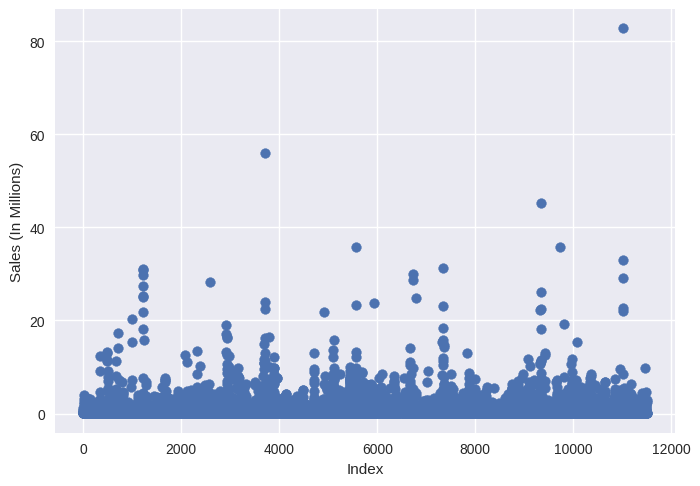

                                               Name         Genre  NA_Sales  \
1005   Brain Age: Train Your Brain in Minutes a Day          Misc      4.75   
1221                 Call of Duty: Advanced Warfare       Shooter     10.44   
1222                        Call of Duty: Black Ops       Shooter     17.59   
1223                      Call of Duty: Black Ops 3       Shooter     11.89   
1224                     Call of Duty: Black Ops II       Shooter     14.08   
1226                           Call of Duty: Ghosts       Shooter     14.92   
1227                 Call of Duty: Modern Warfare 2       Shooter     13.52   
1228                 Call of Duty: Modern Warfare 3       Shooter     15.58   
2591                                      Duck Hunt       Shooter     26.93   
3712                            Grand Theft Auto IV        Action     11.53   
3713                             Grand Theft Auto V        Action     23.46   
3717                  Grand Theft Auto: San Andreas 

In [411]:
print(df['Genre'].unique());
plt.scatter(df.index, df['Global_Sales']);
plt.xlabel("Index");
plt.ylabel("Sales (In Millions)");
plt.show();
print(df[df['Global_Sales'] > 20]);

# Sub-Question 1

**Processing Data**

In [412]:
genre_pivot = pd.pivot_table (
    df,
    index = 'Genre',
    values = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales'],
    aggfunc = 'sum'
);
print(genre_pivot);

              EU_Sales  JP_Sales  NA_Sales  Other_Sales
Genre                                                  
Action          524.86    159.83    877.43       187.33
Adventure        64.09     51.74    105.66        16.79
Fighting        101.32     87.30    223.50        36.68
Misc            215.96    107.72    409.25        75.24
Platform        201.61    130.77    446.96        51.59
Puzzle           50.78     57.31    123.64        12.54
Racing          238.37     56.69    359.33        77.27
Role-Playing    188.06    352.19    327.28        59.61
Shooter         313.25     38.26    582.56       102.69
Simulation      113.38     63.70    183.31        31.52
Sports          376.80    134.97    683.06       134.95
Strategy         45.34     49.37     68.70        11.36


**Graph**

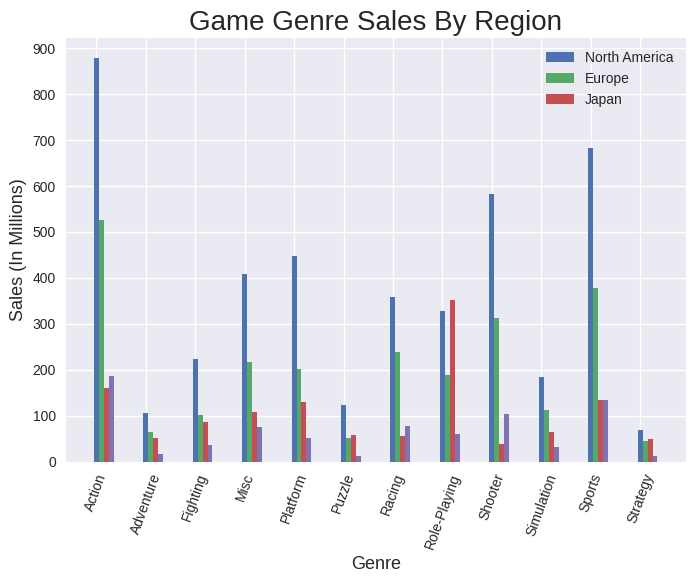

In [413]:
# I made use of the styling in MatPlotLib I researched for the Week 4 Video Presentation
x_axis = np.arange(12);
width = 0.10;
plt.style.use('seaborn-v0_8');
plt.bar(x_axis, genre_pivot['NA_Sales'], width = width);
plt.bar(x_axis + width, genre_pivot['EU_Sales'], width = width);
plt.bar(x_axis + width * 2, genre_pivot['JP_Sales'], width = width,);
plt.bar(x_axis + width * 3, genre_pivot['Other_Sales'], width = width);
plt.xticks(x_axis, ['Action', 'Adventure', 'Fighting', 'Misc', 'Platform', 'Puzzle', 'Racing', 'Role-Playing', 'Shooter', 'Simulation', 'Sports', 'Strategy'], rotation=70, fontsize  = 10);
plt.xlabel("Genre", fontsize = 13);
plt.yticks(np.arange(0, 901, 100));
plt.ylabel('Sales (In Millions)', fontsize = 13);
plt.legend(['North America', 'Europe', 'Japan', 'Other']);
plt.title('Game Genre Sales By Region', fontsize = 20);
plt.tight_layout;
plt.show();

**Results**

The above graph shows the total sales per genre in North America, Europe, and Japan. North America has the highest sales  for each genre, then Europe, and finally Japan. In North America, the top three best-selling genres are Action, Sports, and Shooter. Action has 877.43 million sales in total, Sports games have around 683.06 million total sales, and Shooter games have around 583.56 million total sales. This shows that Action games are particularly popular in North America. In Europe, the top three best-selling genres are Action, Sports, and Shooter as well. Action has 525.86  million total sales, Sports has 377.80 million total sales, and Shooter has 313.25 million total sales. The similar rankings between North America and Europe suggests that these regions have similar genre preferences. Japan has different trends. Their top three best-selling genres are Role-Playing, Action, and Sports. Role-playing has 352.19 million total sales, Action has 160.83 million total sales, and Sports has 135.97 million total sales. Japan, unlike North America and Europe, does not have Shooter amongst its top-selling genres. Instead, Role-Playing games have much higher sales. Outside of these three regions, the best-selling genres are Action, Sports, and Shooter. Action games have sold 187.33 million copies in these other regions, Sports games sold 135.95 million copies in all other regions, and Shooter games sold 103.69 million copies in other regions. This trend is the same as North America and Europe. Overall, Shooter games are very successful in all regions but Japan, while Role-Playing games are the most successful in Japan. North America, Europe, and all other regions than Japan have similar genre sales patterns, while Japan's is different, especially because of the stronger performance of Role-Playing games and the diminished sales of Shooter games.

# Sub-Question 2

**Processing Data**

In [414]:
# I made use of the sort_values() method I learned about in the Module 4 assignment.
best_selling = df.sort_values(by='Global_Sales', ascending=False).head(3);
best_selling = best_selling.drop('Genre', axis=1);
best_selling = best_selling.drop('Global_Sales', axis=1);
print(best_selling);

                     Name  NA_Sales  EU_Sales  JP_Sales  Other_Sales
11011          Wii Sports     41.49     29.02      3.77         8.46
3713   Grand Theft Auto V     23.46     23.04      1.39         8.03
9330    Super Mario Bros.     32.48      4.88      6.96         0.99


**Graph**

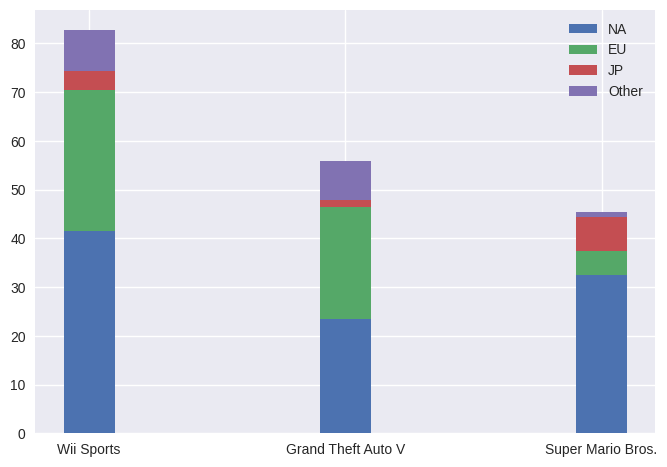

In [415]:
x_axis2 = np.arange(3);
width2 = 0.20
plt.style.use('seaborn-v0_8');
plt.bar(x_axis2, best_selling.iloc[:, 1], width = width2);
plt.bar(x_axis2, best_selling.iloc[:, 2], width = width2, bottom = best_selling.iloc[:, 1]);
plt.bar(x_axis2, best_selling.iloc[:, 3], width = width2, bottom = best_selling.iloc[:, 1] + best_selling.iloc[:, 2]);
plt.bar(x_axis2, best_selling.iloc[:, 4], width = width2, bottom = best_selling.iloc[:, 1] + best_selling.iloc[:, 2] + best_selling.iloc[:, 3]);
plt.legend(['NA', 'EU', 'JP', 'Other']);
plt.xticks(x_axis2, ['Wii Sports', 'Grand Theft Auto V', 'Super Mario Bros.']);
plt.show();

**Results**

The above chart shows the top three best-selling games broken down by region sales. Wii Sports made most of it's sales in North America, with 41.49 million sales from there alone. It made the least of it's sales from Japan, where it only sold 3.77 million copies. Grand Theft Auto V also made most of it's sales in North America, with 23.46 million copies. Europe has very close sale numbers for Grand Theft Auto V, with them having 23.04 million copies sold. The game sold the least in Japan, with only 1.39 million copies sold there. Super Mario Bros also sold best in North America, selling 32.48 million copies. The game sold the least in the aggregation of all regions outside North America, Europe, and Japan, where it sold only 0.99 million copies. Overall, North America contributed to most of the sales of best-selling games. Europe contributed quite a bit to the sales of Wii Sports (selling 29.02 million copies) and Grand Theft Auto V, while Japan contributed more to Supar Mario Bros. in sales than Europe. This shows that, a lot of the sales of these games comes from North America and Europe, with some of Super Mario Bros.' sales coming from Japan. All other regions outside North America, Europe, and Japan did not contribute as much to the sales of these games.

# Sub-Question 3

**Processing Data**

In [416]:
NA_sales_sum = df['NA_Sales'].sum();
EU_sales_sum = df['EU_Sales'].sum();
JP_sales_sum = df['JP_Sales'].sum();
other_sales_sum = df['Other_Sales'].sum();
global_sales_sum = df['Global_Sales'].sum();

NA_sales_percent = round((NA_sales_sum / global_sales_sum) * 100, 2);
EU_sales_percent = round((EU_sales_sum / global_sales_sum) * 100, 2);
JP_sales_percent = round((JP_sales_sum / global_sales_sum) * 100, 2);
other_sales_percent = round((other_sales_sum / global_sales_sum) * 100, 2);

print("North America:", NA_sales_percent, "%");
print("Europe:", EU_sales_percent, "%");
print("Japan:", JP_sales_percent, "%");
print("Other Regions:", other_sales_percent, "%");

North America: 49.24 %
Europe: 27.3 %
Japan: 14.47 %
Other Regions: 8.94 %


**Graph**

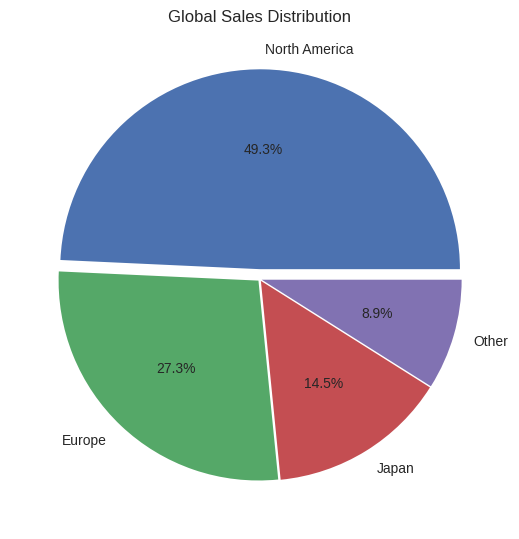

In [417]:
plt.style.use('seaborn-v0_8');
plt.pie(
    [NA_sales_sum, EU_sales_sum, JP_sales_sum, other_sales_sum],
    labels = ['North America', 'Europe', 'Japan', 'Other'],
    explode = [0.05, 0.01, 0.01, 0.01],
    autopct = '%1.1f%%'
);
plt.title('Global Sales Distribution');
plt.tight_layout();
plt.show();


**Result**

The above graph shows the total global sales by region. The region where most game sales happen is in North America, with 49.3 percent of all game sales occuring there. Following this is Europe, who make up 27.3 percent of all global sales. Japan makes up 14.5 percent of all global sales, while the smallest amount of global sales is in the remaining regions, with 8.9 percent of all sales happening there. This shows the biggest market for video games is North America while the smallest market is in others outside North America, Europe, and Japan. While North America makes up almost half of the chart, Europe makes up over a quarter. This shows another big market for video games is in Europe. Japan still has a sizeable market for games while all other regions have the smallest market for video games.

# Summary

In conclusion, gaming preferences and sales do differ over regions. North America contributes the most to global game sales, contributed the most to the success of the top three best-selling games, and holds their top three best-selling genres as Action, Sports, and Shooter. Europe contributes to over a quarter of the global game sales, also contributes quite a bit to the success of games, and holds the same top genres as North America. Japan does contribute to sales as well, but it also must be remembered they are a smaller region than North America and Europe, hence why their contribution is lesser than those two. Japan contributes some to the success of games, but often not a lot. Japan has different top genres than the other regions, having Role-Playing, Action, and Sports as their top genres. In all other regions, their combined sales contributed the least to the global game sales, they contributed the least to the success of games, and the hold the same best-selling genres as North America and Europe. There is a lot more to explore in this topic, however, to make a better conclusion. The biggest topic to look more at is game sales in regions outside North America, Europe, and Japan. The category is very broad and does not tell much about other regions' preferences in games. Another oddity is the big sales figures for Wii Sports in Europe and North America while it did not sell as well in Japan. Wii Sports is a Sports game and, given that Sports is a popular genre in Japan, should have sold better. But the game did the worst in that region. Another point is that this dataset does not include mobile games, only computer and console games. Mobile game downloads could show new patterns and what's more popular with someone not as into video games.